# 03 – Brann og vær: første resultater

Bygger på `python -m src.matching`: hver hendelse er koblet til nærmeste **kjernestasjon** (≥ 80 % dager med temperatur, 449 stasjoner),
og `panel_stasjon_dag` har én rad per stasjon og dag med vær og antall hendelser.

**Rate** = antall hendelser per stasjonsdag. **Relativ rate** = rate i en gruppe delt på gjennomsnittlig rate (1 = vanlig nivå).
Skorsteinsbranner analyseres kun fra 2023, på grunn av bruddet i registreringen.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import pandas as pd, matplotlib.pyplot as plt
from src.db import query
FIG = Path('../figs'); FIG.mkdir(exist_ok=True)
plt.rcParams['figure.figsize'] = (10, 4.5)
GRUPPER = {'n_bygning': ('Brann i bygning', "aar BETWEEN 2016 AND 2026"),
           'n_skorstein': ('Brann i skorstein (2023→)', "aar >= 2023"),
           'n_komfyr': ('Brannhindrende tiltak komfyr', "aar BETWEEN 2016 AND 2026"),
           'n_falske': ('Falske/unødige utrykninger', "aar BETWEEN 2016 AND 2026")}

## 1. Kobling: avstand til nærmeste stasjon (RQ1)

In [2]:
query('''SELECT kilde, count(*) AS hendelser, round(median(avstand_km),1) AS median_km,
       round(quantile_cont(avstand_km,0.9),1) AS p90_km, round(avg((avstand_km<=10)::int),3) AS andel_innen_10km
FROM hendelse_stasjon GROUP BY kilde ORDER BY hendelser DESC''')

,kilde,hendelser,median_km,p90_km,andel_innen_10km
0,falske,556382,3.7,11.9,0.852
1,bygg,69418,4.4,15.4,0.787
2,spredning_til_bygg,459,7.3,19.6,0.647


## 2. Relativ rate etter døgntemperatur (RQ2)

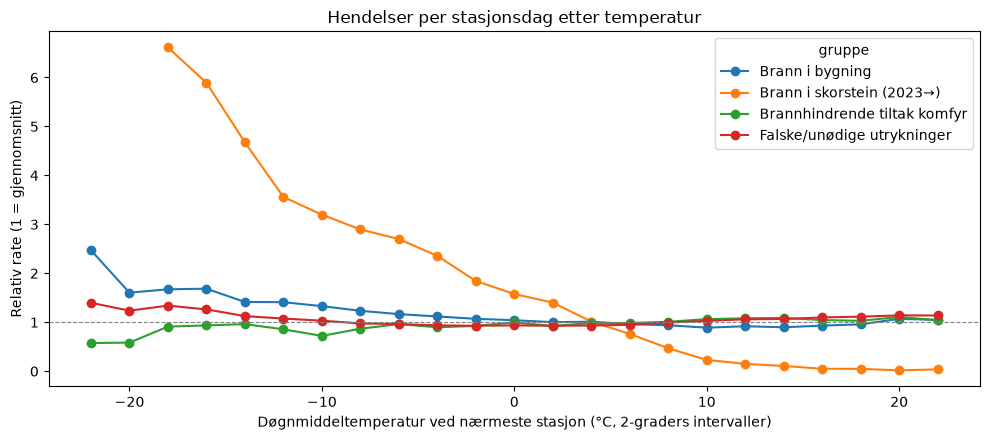

In [3]:
rows = []
for col, (navn, filt) in GRUPPER.items():
    # Indirekte standardisering: forventet antall = stasjonens egen gjennomsnittsrate.
    # Da sammenlignes hver stasjon med seg selv, og forskjeller mellom stasjoner (by/land) fjernes.
    d = query(f'''WITH p AS (
          SELECT {col} AS n, temp_mean, avg({col}) OVER (PARTITION BY stasjon_id) AS forventet
          FROM panel_stasjon_dag WHERE temp_mean IS NOT NULL AND {filt})
        SELECT floor(temp_mean/2)*2 AS temp, sum(n) AS n, sum(forventet) AS forventet, count(*) AS dager
        FROM p GROUP BY 1''')
    d = d[d.dager >= 2000]
    d['rel_rate'] = d.n / d.forventet
    d['gruppe'] = navn
    rows.append(d)
temp = pd.concat(rows).sort_values('temp')
ax = temp.pivot(index='temp', columns='gruppe', values='rel_rate').plot(marker='o')
ax.axhline(1, color='grey', lw=0.8, ls='--')
ax.set_xlabel('Døgnmiddeltemperatur ved nærmeste stasjon (°C, 2-graders intervaller)')
ax.set_ylabel('Relativ rate (1 = gjennomsnitt)')
ax.set_title('Hendelser per stasjonsdag etter temperatur')
plt.tight_layout(); plt.savefig(FIG/'relativ_rate_temperatur.png', dpi=150); plt.show()

In [4]:
temp.pivot(index='temp', columns='gruppe', values='rel_rate').round(2)

gruppe,Brann i bygning,Brann i skorstein (2023→),Brannhindrende tiltak komfyr,Falske/unødige utrykninger
temp,,,,
-22.0,2.47,NaN,0.58,1.40
-20.0,1.60,NaN,0.58,1.24
-18.0,1.67,6.61,0.91,1.34
-16.0,1.69,5.89,0.94,1.26
-14.0,1.41,4.68,0.96,1.13
-12.0,1.41,3.56,0.86,1.07
-10.0,1.33,3.20,0.72,1.03
-8.0,1.23,2.90,0.87,0.98
-6.0,1.17,2.70,0.96,0.96


## 3. Er det temperaturen, eller bare årstiden?
Sesong og menneskelig aktivitet kan forklare mye. Her brukes **temperaturavvik**: dagens temperatur minus snittet for samme stasjon og måned.
Da sammenlignes for eksempel en uvanlig kald januardag med en vanlig januardag på samme sted.

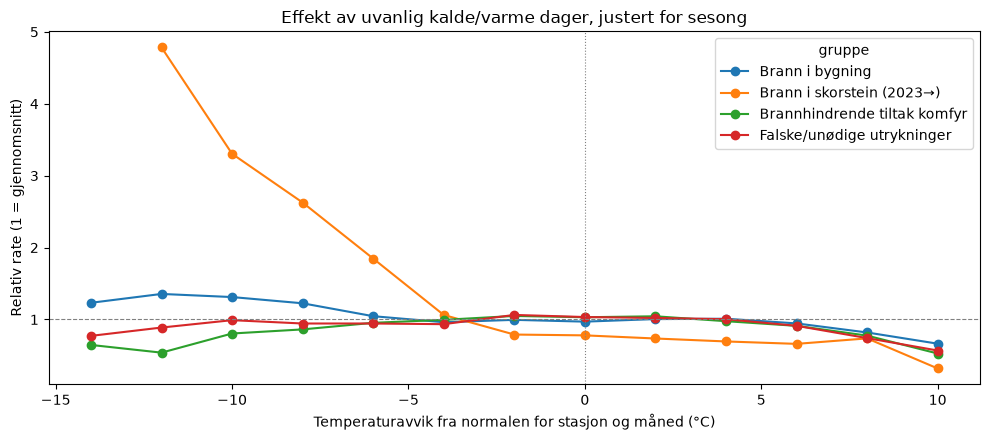

In [5]:
rows = []
for col, (navn, filt) in GRUPPER.items():
    d = query(f'''WITH p AS (
          SELECT {col} AS n, temp_mean - avg(temp_mean) OVER (PARTITION BY stasjon_id, mnd) AS avvik
          FROM panel_stasjon_dag WHERE temp_mean IS NOT NULL AND {filt})
        SELECT floor(avvik/2)*2 AS avvik, sum(n) AS n, count(*) AS dager FROM p GROUP BY 1''')
    d = d[(d.dager >= 2000) & d.avvik.between(-14, 12)]
    d['rel_rate'] = (d.n / d.dager) / (d.n.sum() / d.dager.sum())
    d['gruppe'] = navn
    rows.append(d)
avvik = pd.concat(rows).sort_values('avvik')
ax = avvik.pivot(index='avvik', columns='gruppe', values='rel_rate').plot(marker='o')
ax.axhline(1, color='grey', lw=0.8, ls='--'); ax.axvline(0, color='grey', lw=0.8, ls=':')
ax.set_xlabel('Temperaturavvik fra normalen for stasjon og måned (°C)')
ax.set_ylabel('Relativ rate (1 = gjennomsnitt)')
ax.set_title('Effekt av uvanlig kalde/varme dager, justert for sesong')
plt.tight_layout(); plt.savefig(FIG/'relativ_rate_temperaturavvik.png', dpi=150); plt.show()

In [6]:
avvik.pivot(index='avvik', columns='gruppe', values='rel_rate').round(2)

gruppe,Brann i bygning,Brann i skorstein (2023→),Brannhindrende tiltak komfyr,Falske/unødige utrykninger
avvik,,,,
-14.0,1.23,NaN,0.65,0.77
-12.0,1.36,4.78,0.54,0.89
-10.0,1.31,3.30,0.81,0.99
-8.0,1.23,2.63,0.86,0.94
-6.0,1.05,1.85,0.95,0.94
-4.0,0.96,1.06,1.00,0.93
-2.0,1.00,0.79,1.05,1.06
0.0,0.97,0.78,1.03,1.03
2.0,1.01,0.74,1.04,1.02


## 4. Tidsforsinkelse (lag)
Korrelasjon mellom antall hendelser per stasjonsdag og temperaturavvik samme dag, 1–3 dager før, og snitt siste 7 dager.
Negativ korrelasjon = flere hendelser når det er kaldere enn normalt. Korrelasjonene er små fordi de fleste stasjonsdager har 0 hendelser; det er forskjellen mellom lagene som er interessant.

In [7]:
res = []
for col, (navn, filt) in GRUPPER.items():
    r = query(f'''WITH p AS (
        SELECT {col} AS n, mnd, stasjon_id,
               temp_mean, temp_mean_lag1, temp_mean_lag2, temp_mean_lag3, temp_mean_7d
        FROM panel_stasjon_dag WHERE {filt}),
      a AS (SELECT *, avg(temp_mean) OVER (PARTITION BY stasjon_id, mnd) AS norm FROM p)
      SELECT corr(n, temp_mean - norm) AS lag0, corr(n, temp_mean_lag1 - norm) AS lag1,
             corr(n, temp_mean_lag2 - norm) AS lag2, corr(n, temp_mean_lag3 - norm) AS lag3,
             corr(n, temp_mean_7d - norm) AS snitt_7d FROM a''')
    r.insert(0, 'gruppe', navn); res.append(r)
lag = pd.concat(res).set_index('gruppe').round(4)
lag

,lag0,lag1,lag2,lag3,snitt_7d
gruppe,,,,,
Brann i bygning,-0.0058,-0.0065,-0.0055,-0.0046,-0.0058
Brann i skorstein (2023→),-0.0468,-0.0419,-0.0314,-0.0234,-0.0329
Brannhindrende tiltak komfyr,0.0020,0.0019,0.0014,0.0005,0.0010
Falske/unødige utrykninger,0.0016,0.0014,0.0010,0.0009,0.0022


## 5. Foreløpige funn og forbehold
**Funn (9. nov.–12. nov. 2026, første versjon):**
- **Skorsteinsbranner** øker sterkt med kulde: på dager 8–12 °C kaldere enn normalt for stasjonen og måneden er raten 2,6–4,8 ganger gjennomsnittet. Effekten er sterkest samme dag og avtar over 1–3 dager.
- **Brann i bygning** øker også på uvanlig kalde dager (rundt +20–35 % ved 8–14 °C under normalen), og effekten er like sterk dagen etter (lag 1).
- **Komfyr-hendelser og falske utrykninger** øker *ikke* på uvanlig kalde dager. Som negativ kontroll tyder det på at effekten for skorstein og bygning ikke bare skyldes at folk er mer inne.
- Alle grupper har lavere rate på uvanlig varme dager, trolig fordi folk er mindre hjemme (ferie og utendørs aktivitet).

**Forbehold:**
- Relativ rate er standardisert per stasjon (hver stasjon sammenlignes med seg selv), så forskjeller i befolkning mellom nedslagsfelt påvirker ikke kurvene.
- Ingen statistiske tester ennå (neste steg: Poisson/negativ binomial regresjon med stasjon, måned og ukedag).
- Lokal tid i BRIS vs. UTC i Frost er ikke justert.